# Разведочный анализ данных 
Провести сравнительный разведочный анализ акций и фьючерсов, выявить особенности их ценового поведения и определить потенциально полезные характеристики для дальнейшего прогнозирования с помощью машинного обучения.

Структура анализа:
1. Обзор и проверка качества данных
2. Анализ доходности и волатильности
3. Корреляционный анализ и исследование рыночных режимов
4. Анализ консолидаций (боковых движений рынка)

### 1. Обзор и проверка качества данных

**Обзор данных:**
Данные были загружены через провайдера данных Massive. 
Исследуемые инструменты участника (согласно распределению ../../config/instruments.yaml):

*Акции (30 инструментов):*
- Information Technology — 10 акций.
- Energy — 10 акций.
- Real Estate — 10 акций.

*Фьючерсы (12 инструментов):*
- Agriculture — 8 инструментов.
- Currencies — 4 инструмента.

*Плановый период проекта: 15.11.2021–30.09.2026; фактические границы определяются отдельно.*

In [3]:
# Импорт библиотек 

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml

repo_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "config/instruments.yaml").exists()
    ),
    None
)

if repo_root is None:
    raise FileNotFoundError("Project root not found")

# Основные пути
data_path = repo_root / "data/processed"
stocks_path = data_path / "stocks"
futures_path = data_path / "futures_continuous"

with open(repo_root / "config/instruments.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Назначенные инструменты
my_stocks = {
    sector: [item["ticker"] for item in config["stocks"][sector]]
    for sector in config["team"]["enkira"]["stocks"]
}

my_futures = {
    sector: [item["ticker"] for item in config["futures"][sector]]
    for sector in config["team"]["enkira"]["futures"]
}

print("Project:", repo_root)
print("Stocks:", sum(map(len, my_stocks.values())))
print("Futures:", sum(map(len, my_futures.values())))

print("\nStocks:", my_stocks)
print("\nFutures:", my_futures)

Project: /home/enkira/113-team_Securities-market-prediction
Stocks: 30
Futures: 12

Stocks: {'information_technology': ['NVDA', 'AAPL', 'MSFT', 'AVGO', 'MU', 'AMD', 'INTC', 'PLTR', 'CSCO', 'AMAT'], 'energy': ['XOM', 'CVX', 'COP', 'MPC', 'VLO', 'PSX', 'WMB', 'EOG', 'SLB', 'TRGP'], 'real_estate': ['WELL', 'PLD', 'EQIX', 'AMT', 'SPG', 'DLR', 'O', 'PSA', 'VMRK', 'VTR']}

Futures: {'currencies': ['6J', '6B', '6A', '6S'], 'agriculture': ['ZC', 'ZS', 'ZW', 'ZM', 'ZL', 'LE', 'HE', 'GF']}


### 1.1 Обзор данных 
- Создаем сводную таблицу по всем инструментам (30 акций и 12 фьючерсам) по трем таймфреймам (15мин, 1час, 4часа)
- Для сравнения структуры исходных данных рассмотрим примеры 15-минутных свечей акции NVDA и фьючерса ZC

In [9]:
# Создаем сводную таблицу по всем 42 инструментам (акциям и фьючерсам) и трём таймфреймам

import pyarrow.parquet as pq

timeframes = ["15min", "1hour", "4hour"]

markets = {
    "stocks": (stocks_path, my_stocks),
    "futures": (futures_path, my_futures)
}


def get_time_bounds(parquet):
    """Получаем границы временного ряда из метаданных Parquet."""

    if "time" not in parquet.schema_arrow.names:
        return pd.NaT, pd.NaT

    col_idx = parquet.schema_arrow.names.index("time")
    starts, ends = [], []

    for i in range(parquet.metadata.num_row_groups):
        stats = parquet.metadata.row_group(i).column(col_idx).statistics

        if stats is not None and stats.has_min_max:
            starts.append(pd.to_datetime(stats.min, utc=True))
            ends.append(pd.to_datetime(stats.max, utc=True))

    if not starts:
        return pd.NaT, pd.NaT

    return min(starts), max(ends)


records = []

for market, (directory, groups) in markets.items():
    for group, tickers in groups.items():
        for ticker in tickers:
            for tf in timeframes:

                path = directory / f"{ticker}_{tf}.parquet"
                exists = path.exists()

                rows = 0
                start, end = pd.NaT, pd.NaT

                if exists:
                    parquet = pq.ParquetFile(path)

                    rows = parquet.metadata.num_rows
                    start, end = get_time_bounds(parquet)

                records.append({
                    "market": market,
                    "group": group,
                    "ticker": ticker,
                    "timeframe": tf,
                    "exists": exists,
                    "rows": rows,
                    "start_utc": start,
                    "end_utc": end,
                    "path": str(path)
                })

data_inventory = pd.DataFrame(records)

# Саммари по группам инструментов и таймфреймам
inventory_summary = (
    data_inventory
    .groupby(["market", "group", "timeframe"])
    .agg(
        instruments=("ticker", "nunique"),
        available_files=("exists", "sum"),
        total_bars=("rows", "sum"),
        earliest_start=("start_utc", "min"),
        latest_end=("end_utc", "max")
    )
    .reset_index()
)

display(inventory_summary)

# Показываем отсутствующие файлы
missing_files = data_inventory[~data_inventory["exists"]]

print("\nОтсутствующие файлы:", len(missing_files))

if not missing_files.empty:
    display(
        missing_files[["market", "group", "ticker", "timeframe"]]
    )

# Рассмотрим структуру данных для каждой группы инструментой (акций и фьючерсов) на примере одного тикера
for market, ticker, path in [
    ("Акция", "NVDA", stocks_path / "NVDA_15min.parquet"),
    ("Фьючерс", "ZC", futures_path / "ZC_15min.parquet")
]:
    df = pd.read_parquet(path)

    print(f"\n{market}: {ticker}")
    print(f"Размер: {df.shape}")
    print("Колонки:", df.columns.tolist())
    display(df.head(3))

,market,group,timeframe,instruments,available_files,total_bars,earliest_start,latest_end
0,futures,agriculture,15min,8,8,499511,2021-11-15 01:00:00+00:00,2026-09-30 18:15:00+00:00
1,futures,agriculture,1hour,8,8,137182,2021-11-15 01:00:00+00:00,2026-09-30 18:00:00+00:00
2,futures,agriculture,4hour,8,8,37704,2021-11-15 00:00:00+00:00,2026-09-30 16:00:00+00:00
3,futures,currencies,15min,4,4,462649,2021-11-14 23:00:00+00:00,2026-09-30 20:45:00+00:00
4,futures,currencies,1hour,4,4,115764,2021-11-14 23:00:00+00:00,2026-09-30 20:00:00+00:00
5,futures,currencies,4hour,4,4,35116,2021-11-14 20:00:00+00:00,2026-09-30 20:00:00+00:00
6,stocks,energy,15min,10,10,469779,2021-11-15 09:00:00+00:00,2026-09-30 23:45:00+00:00
7,stocks,energy,1hour,10,10,146979,2021-11-15 09:00:00+00:00,2026-09-30 23:00:00+00:00
8,stocks,energy,4hour,10,10,45064,2021-11-15 09:00:00+00:00,2026-09-30 20:00:00+00:00
9,stocks,information_technology,15min,10,10,712252,2021-11-15 09:00:00+00:00,2026-09-30 23:45:00+00:00



Отсутствующие файлы: 0

Акция: NVDA
Размер: (77886, 22)
Колонки: ['time', 'ticker', 'source_ticker', 'open', 'high', 'low', 'close', 'volume', 'split_adj_open', 'split_adj_high', 'split_adj_low', 'split_adj_close', 'split_adj_volume', 'adj_open', 'adj_high', 'adj_low', 'adj_close', 'vwap', 'trades', 'split_factor', 'dividend_factor', 'in_session']


,time,ticker,source_ticker,open,high,low,close,volume,split_adj_open,split_adj_high,...,split_adj_volume,adj_open,adj_high,adj_low,adj_close,vwap,trades,split_factor,dividend_factor,in_session
0,2021-11-15 09:00:00+00:00,NVDA,NVDA,302.90,303.89,302.01,302.93,7337.0,30.290,30.389,...,73370.0,30.157168,30.255734,30.068558,30.160155,302.7671,377,0.1,0.995615,False
1,2021-11-15 09:15:00+00:00,NVDA,NVDA,302.51,302.71,302.40,302.43,14172.0,30.251,30.271,...,141720.0,30.118339,30.138251,30.107387,30.110374,302.5924,534,0.1,0.995615,False
2,2021-11-15 09:30:00+00:00,NVDA,NVDA,302.48,302.66,302.48,302.66,6426.0,30.248,30.266,...,64260.0,30.115352,30.133273,30.115352,30.133273,302.5566,209,0.1,0.995615,False



Фьючерс: ZC
Размер: (85970, 10)
Колонки: ['time', 'session_end_date', 'contract', 'open', 'high', 'low', 'close', 'volume', 'transactions', 'factor']


,time,session_end_date,contract,open,high,low,close,volume,transactions,factor
0,2021-11-15 01:00:00+00:00,2021-11-15,ZCZ1,689.801110,690.100373,687.407007,688.604059,2056,565,1.197052
1,2021-11-15 01:15:00+00:00,2021-11-15,ZCZ1,688.304796,688.304796,687.107744,688.005533,430,114,1.197052
2,2021-11-15 01:30:00+00:00,2021-11-15,ZCZ1,687.706270,688.005533,687.407007,687.706270,224,58,1.197052


### 1.2 Проверка качества данных

Проверка происходит по всем 42 инструментам и включает в себя следующие элементы:
- Пропуски или некорректные OHLC-значения (invalid_ohlc)
- Дубликаты временных меток (duplicate_time)
- Несогласованные цены открытия, максимума, минимума и закрытия (invalid_prices)
- Переходы между фьючерсными контрактами (contract_rolls)

In [11]:
# Проверим качество 15мин данных

quality_records = []

files_15m = data_inventory[
    (data_inventory["timeframe"] == "15min")
    & data_inventory["exists"]
]

for row in files_15m.itertuples(index=False):

    if row.market == "stocks":
        cols = [
            "time", "in_session",
            "adj_open", "adj_high", "adj_low", "adj_close"
        ]
        o, h, l, c = (
            "adj_open", "adj_high", "adj_low", "adj_close"
        )
    else:
        cols = [
            "time", "contract",
            "open", "high", "low", "close"
        ]
        o, h, l, c = "open", "high", "low", "close"

    df = pd.read_parquet(row.path, columns=cols)

    if row.market == "stocks":
        df = df[df["in_session"] == True].copy()

    prices = df[[o, h, l, c]]

    invalid_prices = (
        (~np.isfinite(prices.to_numpy())).any(axis=1)
        | (prices <= 0).any(axis=1)
    ).sum()

    invalid_ohlc = (
        (df[h] < df[[o, l, c]].max(axis=1))
        | (df[l] > df[[o, h, c]].min(axis=1))
    ).sum()

    duplicate_times = df["time"].duplicated().sum()

    roll_count = (
        (df["contract"] != df["contract"].shift()).sum() - 1
        if row.market == "futures"
        else np.nan
    )

    quality_records.append({
        "ticker": row.ticker,
        "market": row.market,
        "group": row.group,
        "bars": len(df),
        "invalid_prices": invalid_prices,
        "invalid_ohlc": invalid_ohlc,
        "duplicate_times": duplicate_times,
        "contract_rolls": roll_count
    })

quality_15m = pd.DataFrame(quality_records)

display(
    quality_15m.groupby(["market", "group"]).agg(
        instruments=("ticker", "count"),
        total_bars=("bars", "sum"),
        invalid_prices=("invalid_prices", "sum"),
        invalid_ohlc=("invalid_ohlc", "sum"),
        duplicates=("duplicate_times", "sum"),
        contract_rolls=("contract_rolls", "sum")
    )
)

print("\nInstruments with quality issues:")

display(
    quality_15m[
        (quality_15m["invalid_prices"] > 0)
        | (quality_15m["invalid_ohlc"] > 0)
        | (quality_15m["duplicate_times"] > 0)
    ]
) 

instruments  total_bars  invalid_prices  \
market  group                                                             
futures agriculture                       8      499511               0   
        currencies                        4      462649               0   
stocks  energy                           10      316780               0   
        information_technology           10      316780               0   
        real_estate                      10      316773               0   

                                invalid_ohlc  duplicates  contract_rolls  
market  group                                                             
futures agriculture                        0           0           222.0  
        currencies                         0           0            80.0  
stocks  energy                             0           0             0.0  
        information_technology             0           0             0.0  
        real_estate                        0           0             0.0


Instruments with quality issues:


,ticker,market,group,bars,invalid_prices,invalid_ohlc,duplicate_times,contract_rolls


## 2. Анализ доходностей и волатильности

Для акций используются скорректированные цены и только основная торговая сессия NYSE. Для фьючерсов используются цены непрерывных контрактов.

Основное сравнение проводится на общем временном интервале 09:30–13:00 по Нью-Йорку с учётом перехода на летнее и зимнее время. Это делает сравнение более согласованным по времени суток, но результаты характеризуют именно выбранный торговый интервал, а не весь торговый день.

### 2.1 Логарифмическая доходность внутри 15мин свеч:

- Средняя 15-минутная доходность
- Стандартное отклонение доходностей
- Асимметрия и эксцесс распределения
- 99-й процентиль абсолютной доходности

Результаты агрегируются на уровне пяти групп инструментов. Каждому инструменту при групповом сравнении присваивается одинаковый вес.

*Исследовательский вопрос: насколько различаются величина и распределение внутридневных ценовых движений акций и фьючерсов?*

In [16]:
return_records = []

for row in files_15m.itertuples(index=False):

    if row.market == "stocks":
        cols = ["time", "in_session", "adj_open", "adj_close"]
        o, c = "adj_open", "adj_close"
    else:
        cols = ["time", "open", "close"]
        o, c = "open", "close"

    df = pd.read_parquet(row.path, columns=cols)

    # Время Нью-Йорка с учётом DST
    ny_time = pd.to_datetime(
        df["time"], utc=True
    ).dt.tz_convert("America/New_York")

    minutes = ny_time.dt.hour * 60 + ny_time.dt.minute

    # Общее окно 09:30–13:00
    mask = (minutes >= 570) & (minutes < 780)

    if row.market == "stocks":
        mask &= df["in_session"].fillna(False)

    df = df.loc[mask].copy()

    valid = (
        np.isfinite(df[o])
        & np.isfinite(df[c])
        & (df[o] > 0)
        & (df[c] > 0)
    )

    df = df.loc[valid]

    r = np.log(df[c] / df[o]) * 100

    return_records.append({
        "ticker": row.ticker,
        "market": row.market,
        "group": row.group,
        "observations": len(r),
        "mean_return_pct": r.mean(),
        "std_return_pct": r.std(),
        "skewness": r.skew(),
        "excess_kurtosis": r.kurt(),
        "q99_abs_return_pct": r.abs().quantile(0.99)
    })

returns_summary = pd.DataFrame(return_records)

group_returns_summary = (
    returns_summary
    .groupby(["market", "group"])
    .agg(
        instruments=("ticker", "count"),
        median_std_pct=("std_return_pct", "median"),
        median_skewness=("skewness", "median"),
        median_kurtosis=("excess_kurtosis", "median"),
        median_q99_abs_return_pct=("q99_abs_return_pct", "median")
    )
    .reset_index()
)

display(group_returns_summary.round(4))

,market,group,instruments,median_std_pct,median_skewness,median_kurtosis,median_q99_abs_return_pct
0,futures,agriculture,8,0.2901,0.0331,7.9784,0.9562
1,futures,currencies,4,0.0734,0.1182,11.3636,0.2469
2,stocks,energy,10,0.4127,-0.1220,8.0756,1.4288
3,stocks,information_technology,10,0.5443,0.0101,9.2795,1.8902
4,stocks,real_estate,10,0.3205,-0.1648,12.3755,1.0936


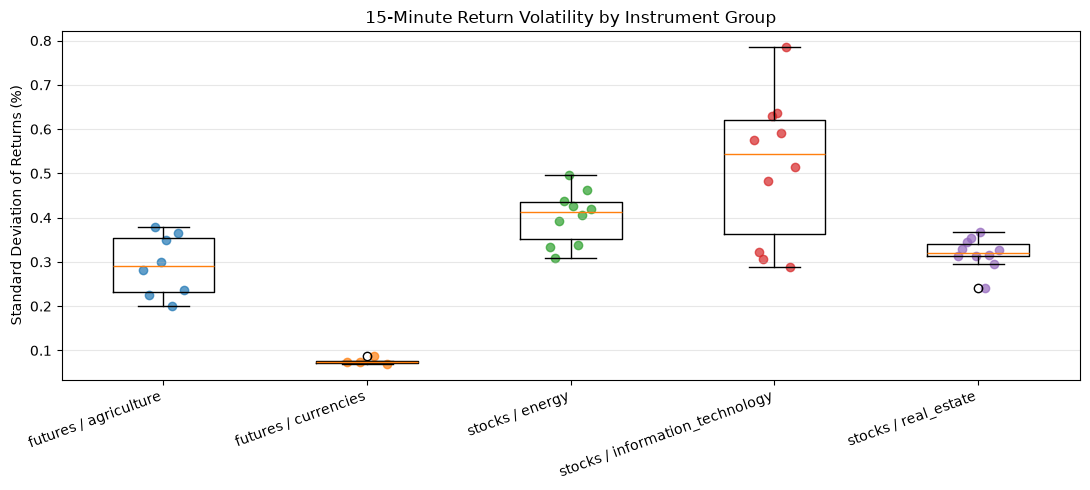

In [17]:
# Распределение волатильности инструментов по группам

groups = list(returns_summary.groupby(["market", "group"]))

labels = [
    f"{market} / {group}"
    for (market, group), _ in groups
]

values = [
    df["std_return_pct"].to_numpy()
    for _, df in groups
]

fig, ax = plt.subplots(figsize=(11, 5))

ax.boxplot(values)

# Показываем отдельные инструменты
for i, vals in enumerate(values, start=1):
    ax.scatter(
        np.linspace(i - 0.1, i + 0.1, len(vals)),
        vals,
        alpha=0.7
    )

ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels, rotation=20, ha="right")

ax.set_title("15-Minute Return Volatility by Instrument Group")
ax.set_ylabel("Standard Deviation of Returns (%)")

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Основные выводы доходности:
- Наблюдается существенная разница в волатильности между группами инструментов: IT акции (0,5443%) vs Валютные фьючерсы (0,0734%)
- Распределение доходностей характеризируется тяжелыми хвостами: во всех пяти группах наблюдается положительный эксцесс, медианные значения которого составляют от 7,98 до 12,38
- Выраженной асимметрии доходностей на уровне групп не обнаружено

### 2.2 Внутридневная и календарная динамика волатильности

Цель: выявить временные закономерности волатильности акций и фьючерсов и проверить их устойчивость.

Исследовательские вопросы:

- Как меняется волатильность в течение торгового дня?
- Различается ли внутридневная динамика волатильности между акциями и фьючерсами?
- Сохраняются ли обнаруженные внутридневные закономерности в разные годы?

In [18]:
# Рассчитываем доходности с учётом времени суток

intraday_data = []

for row in files_15m.itertuples(index=False):

    if row.market == "stocks":
        cols = ["time", "in_session", "adj_open", "adj_close"]
        o, c = "adj_open", "adj_close"
    else:
        cols = ["time", "open", "close"]
        o, c = "open", "close"

    df = pd.read_parquet(row.path, columns=cols)

    
    ny_time = pd.to_datetime(
        df["time"], utc=True
    ).dt.tz_convert("America/New_York")

    minutes = ny_time.dt.hour * 60 + ny_time.dt.minute

    
    mask = (
        (minutes >= 570)
        & (minutes < 780)
        & (ny_time.dt.dayofweek < 5)
    )

    if row.market == "stocks":
        mask &= df["in_session"].fillna(False)

    # Проверяем цены
    mask &= (
        np.isfinite(df[o])
        & np.isfinite(df[c])
        & (df[o] > 0)
        & (df[c] > 0)
    )

    r = np.log(df.loc[mask, c] / df.loc[mask, o]) * 100

    intraday_data.append(pd.DataFrame({
        "ticker": row.ticker,
        "market": row.market,
        "group": row.group,
        "year": ny_time.loc[mask].dt.year,
        "weekday": ny_time.loc[mask].dt.dayofweek,
        "minute": minutes.loc[mask],
        "return_pct": r
    }))

intraday_returns = pd.concat(
    intraday_data, ignore_index=True
)

print("Total observations:", len(intraday_returns))
print("Instruments:", intraday_returns["ticker"].nunique())

display(intraday_returns.head())

Total observations: 721273
Instruments: 42


,ticker,market,group,year,weekday,minute,return_pct
0,NVDA,stocks,information_technology,2021,0,570,-1.361611
1,NVDA,stocks,information_technology,2021,0,585,-0.147831
2,NVDA,stocks,information_technology,2021,0,600,-0.127988
3,NVDA,stocks,information_technology,2021,0,615,-0.625675
4,NVDA,stocks,information_technology,2021,0,630,0.066189


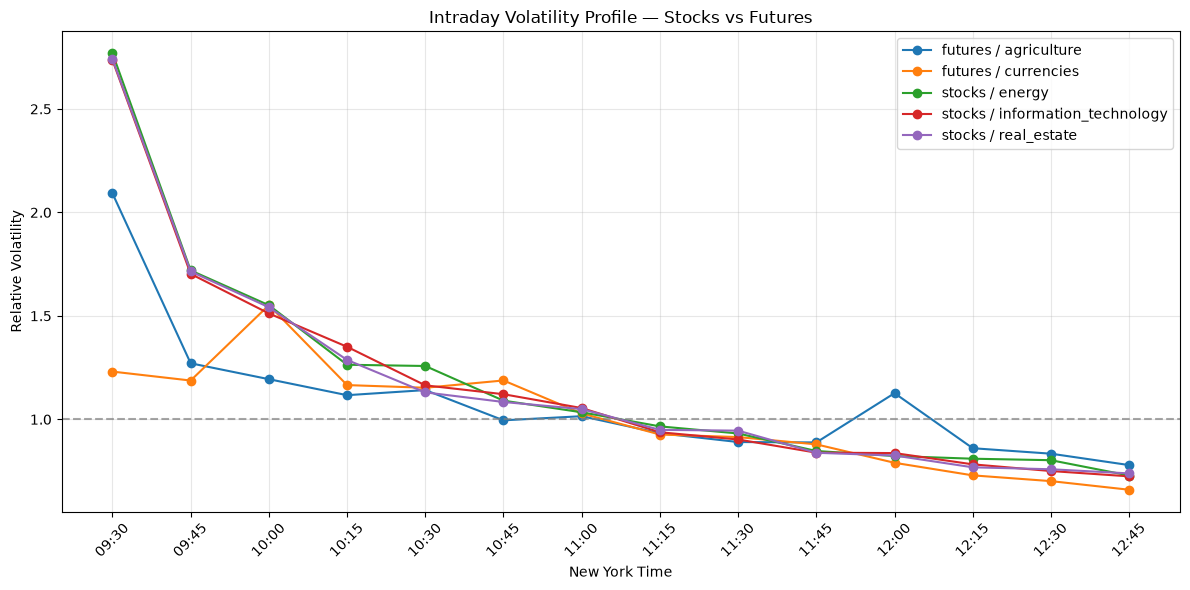

In [19]:
# Волатильность в течение торгового дня

# Волатильность каждого инструмента по 15-минутным интервалам
intraday_profile = (
    intraday_returns
    .groupby(["market", "group", "ticker", "minute"])
    ["return_pct"]
    .agg(["std", "count"])
    .reset_index()
)

# Исключаем интервалы с недостаточным числом наблюдений
intraday_profile = intraday_profile[
    intraday_profile["count"] >= 20
].copy()

baseline = (
    intraday_profile
    .groupby(["market", "group", "ticker"])["std"]
    .transform("median")
)

intraday_profile["relative_volatility"] = (
    intraday_profile["std"] / baseline
)

# Медиана по инструментам внутри группы
group_intraday = (
    intraday_profile
    .groupby(["market", "group", "minute"])
    ["relative_volatility"]
    .median()
    .reset_index()
)


fig, ax = plt.subplots(figsize=(12, 6))

for (market, group), df in group_intraday.groupby(
    ["market", "group"]
):
    ax.plot(
        df["minute"],
        df["relative_volatility"],
        marker="o",
        label=f"{market} / {group}"
    )

ax.axhline(1, color="gray", linestyle="--", alpha=0.7)

minutes = np.arange(570, 780, 15)

ax.set_xticks(minutes)
ax.set_xticklabels([
    f"{m // 60:02d}:{m % 60:02d}"
    for m in minutes
], rotation=45)

ax.set_title("Intraday Volatility Profile — Stocks vs Futures")
ax.set_xlabel("New York Time")
ax.set_ylabel("Relative Volatility")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# Устойчивость внутридневной закономерности по годам
period_mask = (
    intraday_returns["minute"].between(570, 629)
    | intraday_returns["minute"].between(720, 779)
)

yearly_data = intraday_returns.loc[period_mask].copy()

yearly_data["period"] = np.where(
    yearly_data["minute"] < 630,
    "Opening hour",
    "Midday hour"
)

yearly_stats = (
    yearly_data
    .groupby(["market", "group", "ticker", "year", "period"])
    ["return_pct"]
    .agg(["std", "count"])
    .reset_index()
)

# Не учитываем периоды с менее чем 50 свечами
yearly_stats = yearly_stats[yearly_stats["count"] >= 50]

yearly_pivot = yearly_stats.pivot(
    index=["market", "group", "ticker", "year"],
    columns="period",
    values="std"
)

yearly_pivot["opening_midday_ratio"] = (
    yearly_pivot["Opening hour"] /
    yearly_pivot["Midday hour"]
)

yearly_summary = (
    yearly_pivot
    .groupby(["market", "group", "year"])
    ["opening_midday_ratio"]
    .median()
    .unstack("year")
)

print("\nOpening Hour / Midday Volatility Ratio by Year:")
display(yearly_summary.round(3))


Opening Hour / Midday Volatility Ratio by Year:


year                             2021   2022   2023   2024   2025   2026
market  group                                                           
futures agriculture             1.747  1.701  1.484  1.521  1.616  1.661
        currencies              1.463  1.759  2.002  1.914  1.687  1.711
stocks  energy                  2.429  2.245  2.347  2.447  2.558  2.442
        information_technology  2.337  2.223  2.459  2.440  2.438  2.659
        real_estate             2.181  2.428  2.371  2.572  2.570  2.516

### Основные выводы: внутридневная динамика волатильности

- Волатильность существенно изменяется в течение торгового дня: для всех пяти групп инструментов наблюдается повышенная волатильность в период 09:30–10:30 по Нью-Йорку по сравнению с 12:00–13:00
- Акции демонстрируют схожую внутридневную динамику волатильности по сравнению с динамикой фьючерсов
- Повышенная волатильность в начале основной торговой сессии NYSE является устойчивой исторической закономерностью: Во всех пяти группах инструментов отношение волатильности периода 09:30–10:30 к волатильности периода 12:00–13:00 превышало единицу во все исследуемые годы (2021–2026)
- Различия между днями недели менее выражены (результаты не были продемонстрированы ввиду незначительных выводов)

**Значение для ML анализа** - результаты указывают на потенциальную полезность времени суток в качестве признака для прогнозирования величины последующих ценовых движений

## 3. Анализ рыночных режимов

### 3.1. Определение рыночных режимов с помощью ADX и CHOP

**Исследовательские вопросы:**

- Какие группы инструментов чаще демонстрируют признаки трендового движения?
- Какие группы чаще характеризуются отсутствием выраженного тренда?
- Насколько различаются рыночные режимы акций и фьючерсов?

**Методология**

Используются два технических индикатора:

- ADX (Average Directional Index) — измеряет силу тренда независимо от его направления
- CHOP (Choppiness Index) — характеризует степень направленности или хаотичности ценового движения


Для первоначальной классификации используются следующие условия:

| Рыночное состояние |	ADX |	CHOP |
| --- | --- | ---|
| Тренд |	≥ 25 |	≤ 38,2 |
| Боковое движение |	< 20 |	≥ 61,8 |
| Неопределённое состояние |	Остальные комбинации |

*Пороговые значения рассматриваются как предварительные эвристики, а не универсальные критерии рыночных режимов.*

In [ ]:
# Рассчитываем индикаторы режима рынка (ADX и CHOP) для 15мин свечей - LLM-driven

def calculate_regime_indicators(df, n=14):
    """ADX и CHOP для 15-минутных свечей."""

    df = df.copy()

    high = df["high"]
    low = df["low"]
    close = df["close"]

    # Не учитываем ночные гэпы при расчёте True Range и Directional Movement
    new_day = df["ny_date"].ne(df["ny_date"].shift())

    prev_close = close.shift().where(~new_day)

    tr = pd.concat([
        high - low,
        (high - prev_close).abs(),
        (low - prev_close).abs()
    ], axis=1).max(axis=1)

    # Directional Movement
    up = high.diff().where(~new_day)
    down = -low.diff().where(~new_day)

    plus_dm = pd.Series(
        np.where((up > down) & (up > 0), up, 0.0),
        index=df.index
    )

    minus_dm = pd.Series(
        np.where((down > up) & (down > 0), down, 0.0),
        index=df.index
    )

    # Сглаживание по методу Wilder (EWMA-приближение) - chatgpt-driven
    def smooth(series):
        return series.ewm(
            alpha=1/n,
            adjust=False,
            min_periods=n
        ).mean()

    atr = smooth(tr)

    plus_di = 100 * smooth(plus_dm) / atr.replace(0, np.nan)
    minus_di = 100 * smooth(minus_dm) / atr.replace(0, np.nan)

    dx = (
        100 * (plus_di - minus_di).abs()
        / (plus_di + minus_di).replace(0, np.nan)
    )

    df["adx"] = smooth(dx)

    # CHOP рассчитываем отдельно внутри каждого торгового дня
    by_day = df["ny_date"]

    sum_tr = tr.groupby(by_day).transform(
        lambda x: x.rolling(n, min_periods=n).sum()
    )

    highest = high.groupby(by_day).transform(
        lambda x: x.rolling(n, min_periods=n).max()
    )

    lowest = low.groupby(by_day).transform(
        lambda x: x.rolling(n, min_periods=n).min()
    )

    price_range = (highest - lowest).replace(0, np.nan)

    df["chop"] = (
        100 * np.log10(sum_tr / price_range) / np.log10(n)
    )

    return df

In [35]:
reference = pd.read_parquet(
    stocks_path / "NVDA_15min.parquet",
    columns=["time", "in_session"]
)

reference_time = pd.to_datetime(
    reference["time"], utc=True
).dt.tz_convert("America/New_York")

stock_dates = set(
    reference_time.loc[
        reference["in_session"].fillna(False)
    ].dt.date
)

regime_results = []

for row in files_15m.itertuples(index=False):

    if row.market == "stocks":
        cols = [
            "time", "in_session",
            "adj_high", "adj_low", "adj_close"
        ]
    else:
        cols = [
            "time", "contract",
            "high", "low", "close"
        ]

    df = pd.read_parquet(row.path, columns=cols)

    ny_time = pd.to_datetime(
        df["time"], utc=True
    ).dt.tz_convert("America/New_York")

    minute = ny_time.dt.hour * 60 + ny_time.dt.minute

    
    mask = (
        (minute >= 570)
        & (minute < 780)
        & ny_time.dt.date.isin(stock_dates)
    )

    if row.market == "stocks":
        mask &= df["in_session"].fillna(False)

    df = df.loc[mask].copy()

    df["ny_date"] = ny_time.loc[mask].dt.date
    df["minute"] = minute.loc[mask]

    if row.market == "stocks":
        df = df.rename(columns={
            "adj_high": "high",
            "adj_low": "low",
            "adj_close": "close"
        })

    df = df.sort_values("time").reset_index(drop=True)

    
    if row.market == "futures":
        segment = df["contract"].ne(df["contract"].shift()).cumsum()
    else:
        segment = pd.Series(1, index=df.index)

    
    same_day = df["ny_date"].eq(df["ny_date"].shift())

    time_diff_seconds = (
        pd.to_datetime(df["time"], utc=True)
        .diff()
        .dt.total_seconds()
    )

    missing_bar = same_day & time_diff_seconds.ne(900)

    segment = segment + missing_bar.cumsum()

    parts = []

    for _, part in df.groupby(segment, sort=False):
        parts.append(calculate_regime_indicators(part))

    if not parts:
        continue

    result = pd.concat(parts).sort_index()

    # Оставляем только полные окна из 14 свечей
    day_size = result.groupby(
        [segment.loc[result.index], "ny_date"]
    )["minute"].transform("size")

    result = result.loc[
        (result["minute"] == 765)
        & (day_size == 14)
    ].copy()

    result["ticker"] = row.ticker
    result["market"] = row.market
    result["group"] = row.group

    regime_results.append(
        result[
            ["ticker", "market", "group", "ny_date", "adx", "chop"]
        ]
    )

regime_data = pd.concat(regime_results, ignore_index=True)

# Исключаем наблюдения, для которых индикаторы ещё не рассчитаны
regime_data = regime_data.dropna(subset=["adx", "chop"]).copy()

# Классификация рыночных режимов
conditions = [
    (regime_data["adx"] >= 25) & (regime_data["chop"] <= 38.2),
    (regime_data["adx"] < 20) & (regime_data["chop"] >= 61.8)
]

regime_data["regime"] = np.select(
    conditions,
    ["trend", "sideways"],
    default="transition"
)

print("Instruments:", regime_data["ticker"].nunique())
print("Observations:", len(regime_data))

display(regime_data.head())

Instruments: 42
Observations: 50984


,ticker,market,group,ny_date,adx,chop,regime
1,NVDA,stocks,information_technology,2021-11-16,36.840165,53.858091,transition
2,NVDA,stocks,information_technology,2021-11-17,32.847891,39.851107,transition
3,NVDA,stocks,information_technology,2021-11-18,35.479901,60.634507,transition
4,NVDA,stocks,information_technology,2021-11-19,21.685500,45.298980,transition
5,NVDA,stocks,information_technology,2021-11-22,27.911969,38.194419,trend


In [32]:
# Проверяем ADX и CHOP по отдельности

diagnostics = regime_data.copy()

diagnostics["adx_trend"] = diagnostics["adx"] >= 25
diagnostics["chop_trend"] = diagnostics["chop"] <= 38.2

diagnostics["adx_sideways"] = diagnostics["adx"] < 20
diagnostics["chop_sideways"] = diagnostics["chop"] >= 61.8

diagnostics["both_trend"] = (
    diagnostics["adx_trend"] & diagnostics["chop_trend"]
)

diagnostics["both_sideways"] = (
    diagnostics["adx_sideways"] & diagnostics["chop_sideways"]
)

columns = [
    "adx_trend", "chop_trend", "both_trend",
    "adx_sideways", "chop_sideways", "both_sideways"
]

# Сначала считаем доли для каждого инструмента
instrument_diagnostics = (
    diagnostics
    .groupby(["market", "group", "ticker"])[columns]
    .mean()
    * 100
)

# Затем усредняем по группам
group_diagnostics = (
    instrument_diagnostics
    .groupby(["market", "group"])
    .mean()
)

display(group_diagnostics.round(1))

adx_trend  chop_trend  both_trend  \
market  group                                                       
futures agriculture                  48.6        16.0        12.5   
        currencies                   48.8        14.5        12.3   
stocks  energy                       45.9        19.7        14.7   
        information_technology       46.4        17.3        13.4   
        real_estate                  44.2        18.7        13.5   

                                adx_sideways  chop_sideways  both_sideways  
market  group                                                               
futures agriculture                     30.6            6.9            3.2  
        currencies                      31.7            8.6            4.7  
stocks  energy                          33.1            4.2            2.2  
        information_technology          33.4            5.5            3.0  
        real_estate                     35.2            4.5            2.7

### Основные выводы по определению рыночных режимов

Анализ ADX и CHOP показал, что результаты классификации существенно зависят от выбранных индикаторов и пороговых значений:

- При использовании ADX ≥ 25 признаки выраженного тренда обнаруживаются примерно в 44-49% наблюдений, тогда как критерий CHOP ≤ 38,2 выполняется только в 14-20% наблюдений.

- Аналогичная ситуация наблюдается при определении боковых состояний: ADX < 20 выполняется приблизительно в 31-35% наблюдений, тогда как CHOP ≥ 61,8 - только в 4-9%.

- При одновременном применении обоих индикаторов большая часть наблюдений оказывается в неопределённой категории.

Таким образом, выбранная комбинация порогов является слишком ограничительной для полноценного исследования частоты консолидаций.

**Решение для дальнейшего исследования:** использовать ADX и CHOP как дополнительные характеристики рынка, а обнаружение консолидаций проводить с помощью отдельного алгоритма, учитывающего ширину ценового диапазона, продолжительность бокового движения и отсутствие выраженного направленного изменения цены.

## 4. Анализ консолидаций
Цель - выявить периоды консолидации на фондовом и фьючерсном рынках и исследовать различия в их распространённости между группами инструментов

### 4.1 Определение консолидаций на основе ценового диапазона

**Исследовательские вопросы:**

- Как часто акции и фьючерсы демонстрируют признаки консолидации?
- Какие группы инструментов чаще находятся в ограниченном ценовом диапазоне?
- Насколько различаются характеристики консолидаций между рынками?

**Методология**

Консолидация определяется как период, в течение которого цена колеблется внутри относительно узкого диапазона без значительного результирующего направленного движения. Следующие индикаторы были выбраны для детекции консолидаций:

1. Относительная ширина диапазона (Range / ATR)

$$[RangeRatio_t = \frac{\max(High)-\min(Low)}{ATR_{14}}] $$

Показатель характеризует ширину ценового диапазона за последние 8 свечей относительно текущей средней истинной амплитуды движения.

2. Относительное направленное смещение (Net Movement / Range)

$$ [NetRatio_t = \frac{|Close_t-Open_{t-7}|}{\max(High)-\min(Low)}] $$

Показатель характеризует результирующее перемещение цены относительно полного диапазона колебаний за последние 8 свечей.

Консолидация определяется при одновременном выполнении условий:

- Количество свечей в исследуемом окне: 8 (2 часа)
- Range / ATR ≤ 0,5; 0,7; 0,9 (проведен анализ чувствительности)
- Net Movement / Range ≤ 0,35



Для проверки и валидации найденных отрезков консолидации был использовать индикатор Relative Volume at Time (RVOL):

$$RVOL_{8,t} = \frac{\sum_{i=0}^{7} Volume_{t-i}}{\operatorname{Median}\left(HistoricalVolume_{8,\text{same\_time}}\right)}$$

Показатель характеризирует объём торгов относительно исторического уровня для выявления нестандартной низкой или высокой активности. Мы сравниваем объём за последние восемь свечей с историческим объёмом аналогичных восьмисвечных окон, заканчивающихся в то же время суток. (https://www.tradingview.com/support/solutions/43000705489-relative-volume-at-time/?utm)

In [51]:
# Параметры алгоритма - LLM-driven
N_BARS = 8
HISTORY = 60
MIN_HISTORY = 30

RANGE_THRESHOLD = 0.7
NET_THRESHOLD = 0.35



reference = pd.read_parquet(
    stocks_path / "NVDA_15min.parquet",
    columns=["time", "in_session"]
)

reference_time = pd.to_datetime(
    reference["time"], utc=True
).dt.tz_convert("America/New_York")

stock_dates = set(
    reference_time.loc[
        reference["in_session"].fillna(False)
    ].dt.date
)


# Обрабатываем все инструменты
results = []

for row in files_15m.itertuples(index=False):

    if row.market == "stocks":
        cols = [
            "time", "in_session", "volume",
            "adj_open", "adj_high", "adj_low", "adj_close"
        ]
    else:
        cols = [
            "time", "contract", "volume",
            "open", "high", "low", "close"
        ]

    df = pd.read_parquet(row.path, columns=cols)
    df["time"] = pd.to_datetime(df["time"], utc=True)

    ny_time = df["time"].dt.tz_convert("America/New_York")
    minute = ny_time.dt.hour * 60 + ny_time.dt.minute

    # Общее окно 09:30–13:00 по Нью-Йорку
    mask = (
        minute.between(570, 779)
        & ny_time.dt.date.isin(stock_dates)
    )

    if row.market == "stocks":
        mask &= df["in_session"].fillna(False)

    df = df.loc[mask].copy()

    if row.market == "stocks":
        df = df.rename(columns={
            "adj_open": "open",
            "adj_high": "high",
            "adj_low": "low",
            "adj_close": "close"
        })

    # Исключаем некорректные ценовые свечи
    prices = df[["open", "high", "low", "close"]]

    valid = (
        np.isfinite(prices).all(axis=1)
        & (prices > 0).all(axis=1)
        & (df["high"] >= df[["open", "low", "close"]].max(axis=1))
        & (df["low"] <= df[["open", "high", "close"]].min(axis=1))
    )

    df = df.loc[valid].sort_values("time").reset_index(drop=True)

    if df.empty:
        continue

    if df["time"].duplicated().any():
        raise ValueError(f"Duplicate timestamps: {row.ticker}")

    ny_time = df["time"].dt.tz_convert("America/New_York")
    df["ny_date"] = ny_time.dt.date
    df["minute"] = ny_time.dt.hour * 60 + ny_time.dt.minute

    # Не допускаем окна через ночь, пропуски и смену контракта
    new_segment = (
        df["ny_date"].ne(df["ny_date"].shift())
        | df["time"].diff().dt.total_seconds().ne(900)
    )

    if row.market == "futures":
        new_segment |= df["contract"].ne(df["contract"].shift())

    df["segment"] = new_segment.cumsum()

    # Ценовой диапазон последних 8 свечей
    group = df.groupby("segment")

    highest = group["high"].transform(
        lambda s: s.rolling(N_BARS, min_periods=N_BARS).max()
    )

    lowest = group["low"].transform(
        lambda s: s.rolling(N_BARS, min_periods=N_BARS).min()
    )

    first_open = group["open"].shift(N_BARS - 1)
    width = highest - lowest

    df["range_pct"] = width / df["close"] * 100

    df["net_fraction"] = (
        (df["close"] - first_open).abs()
        / width.replace(0, np.nan)
    )

    # Историческая медиана диапазона:
    # предыдущие 60 сессий, аналогичное время суток
    df["historical_range_pct"] = (
        df.groupby("minute")["range_pct"]
        .transform(
            lambda s: s.shift(1).rolling(
                HISTORY, min_periods=MIN_HISTORY
            ).median()
        )
    )

    df["relative_range"] = (
        df["range_pct"]
        / df["historical_range_pct"].replace(0, np.nan)
    )

    # Объём за последние 8 последовательных свечей
    df["volume_8"] = (
        df.groupby("segment")["volume"]
        .transform(
            lambda s: s.rolling(N_BARS, min_periods=N_BARS).sum()
        )
    )

    # Исторический объём аналогичного окна
    df["historical_volume_8"] = (
        df.groupby("minute")["volume_8"]
        .transform(
            lambda s: s.shift(1).rolling(
                HISTORY, min_periods=MIN_HISTORY
            ).median()
        )
    )

    df["rvol"] = (
        df["volume_8"]
        / df["historical_volume_8"].replace(0, np.nan)
    )

    # Достаточно ли данных для обнаружения консолидации?
    df["eligible"] = (
        np.isfinite(df["relative_range"])
        & np.isfinite(df["net_fraction"])
        & (width > 0)
    )

    # Итоговый сигнал
    df["consolidation_signal"] = (
        df["eligible"]
        & (df["relative_range"] <= RANGE_THRESHOLD)
        & (df["net_fraction"] <= NET_THRESHOLD)
    )

    df["ticker"] = row.ticker
    df["market"] = row.market
    df["group"] = row.group

    results.append(df[
        [
            "time", "ny_date", "minute", "segment",
            "ticker", "market", "group",
            "open", "high", "low", "close", "volume",
            "range_pct", "relative_range", "net_fraction",
            "rvol", "eligible", "consolidation_signal"
        ]
    ])


consolidation_data = pd.concat(results, ignore_index=True)

print("Instruments:", consolidation_data["ticker"].nunique())
print("Eligible windows:", consolidation_data["eligible"].sum())
print("Consolidation signals:",
      consolidation_data["consolidation_signal"].sum())

display(consolidation_data.head())

Instruments: 42
Eligible windows: 350607
Consolidation signals: 34634


,time,ny_date,minute,segment,ticker,market,group,open,high,low,close,volume,range_pct,relative_range,net_fraction,rvol,eligible,consolidation_signal
0,2021-11-15 14:30:00+00:00,2021-11-15,570,1,NVDA,stocks,information_technology,30.418019,30.509616,29.868440,30.006651,3808256.0,NaN,NaN,NaN,NaN,False,False
1,2021-11-15 14:45:00+00:00,2021-11-15,585,1,NVDA,stocks,information_technology,29.999025,30.149203,29.854501,29.954710,2234596.0,NaN,NaN,NaN,NaN,False,False
2,2021-11-15 15:00:00+00:00,2021-11-15,600,1,NVDA,stocks,information_technology,29.968001,30.103405,29.866449,29.929670,1647441.0,NaN,NaN,NaN,NaN,False,False
3,2021-11-15 15:15:00+00:00,2021-11-15,615,1,NVDA,stocks,information_technology,29.929670,29.965005,29.725071,29.742992,1827441.0,NaN,NaN,NaN,NaN,False,False
4,2021-11-15 15:30:00+00:00,2021-11-15,630,1,NVDA,stocks,information_technology,29.743032,29.841986,29.671318,29.762725,1464876.0,NaN,NaN,NaN,NaN,False,False


Consolidation Frequency (%)


threshold                        0.5    0.7    0.9
market  group                                     
futures agriculture             1.62   9.28  20.15
        currencies              1.94  10.60  20.28
stocks  energy                  1.52   9.46  20.16
        information_technology  2.32  10.53  20.61
        real_estate             1.71   9.52  20.13

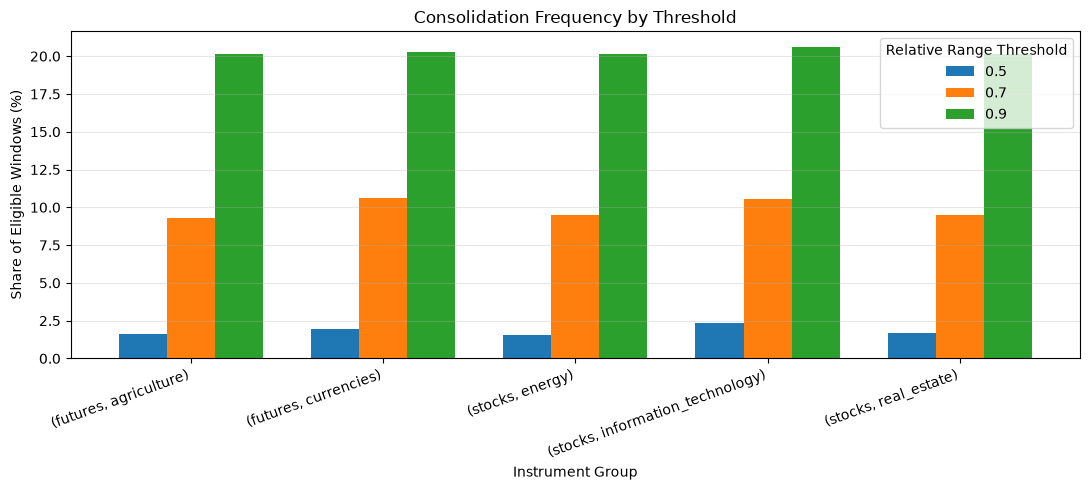

In [52]:
# Только окна с достаточной историей
data = consolidation_data[
    consolidation_data["eligible"]
].copy()

thresholds = [0.5, 0.7, 0.9]

frequency_results = []

for threshold in thresholds:

    data["signal"] = (
        (data["relative_range"] <= threshold)
        & (data["net_fraction"] <= NET_THRESHOLD)
    )

    # Доля сигналов для каждого инструмента
    per_instrument = (
        data.groupby(["market", "group", "ticker"])["signal"]
        .mean()
        .mul(100)
        .reset_index(name="signal_pct")
    )

    # Медиана по группе инструментов
    summary = (
        per_instrument
        .groupby(["market", "group"])["signal_pct"]
        .median()
        .reset_index()
    )

    summary["threshold"] = threshold
    frequency_results.append(summary)


frequency_summary = pd.concat(
    frequency_results, ignore_index=True
)

frequency_table = frequency_summary.pivot(
    index=["market", "group"],
    columns="threshold",
    values="signal_pct"
)

print("Consolidation Frequency (%)")
display(frequency_table.round(2))


# График чувствительности к порогам
ax = frequency_table.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75
)

ax.set_title("Consolidation Frequency by Threshold")
ax.set_xlabel("Instrument Group")
ax.set_ylabel("Share of Eligible Windows (%)")

ax.legend(title="Relative Range Threshold")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Анализ показал, что частота обнаружения консолидационных сигналов существенно зависит от порогового значения Relative Range:

- При пороге **0,5**:   доля сигналов составляет **1,52–2,32%** подходящих восьмисвечных окон
- При пороге **0,7**:   доля сигналов составляет **9,28–10,60%** подходящих восьмисвечных окон
- При пороге **0,9**:   доля сигналов составляет **20,13-20,61%** подходящих восьмисвечных окон

Несмотря на высокую чувствительность абсолютной частоты сигналов к порогу, различия между пятью группами инструментов остаются относительно небольшими при всех трёх значениях.

Методологическое ограничение: полученные результаты отражают частоту выполнения заданных критериев, а не фактическую долю времени, проведённого рынком в консолидации. Перекрывающиеся окна могут относиться к одному рыночному событию.

Для дальнейшего анализа в качестве базового используется порог Relative Range ≤ 0,7 и Net Movement / Range ≤ 0,35. Эти значения являются предварительными исследовательскими параметрами, а не оптимизированными критериями консолидации.

In [53]:
# Только наблюдения с корректным RVOL
volume_analysis = consolidation_data[
    consolidation_data["eligible"]
    & np.isfinite(consolidation_data["rvol"])
    & (consolidation_data["rvol"] >= 0)
].copy()


# Медианный RVOL каждого инструмента
# внутри и вне консолидаций
instrument_rvol = (
    volume_analysis
    .groupby(
        ["market", "group", "ticker", "consolidation_signal"]
    )["rvol"]
    .median()
    .unstack("consolidation_signal")
    .reindex(columns=[False, True])
)

instrument_rvol.columns = [
    "no_consolidation",
    "consolidation"
]


# Изменение RVOL для каждого инструмента
instrument_rvol["difference_pct"] = (
    instrument_rvol["consolidation"]
    / instrument_rvol["no_consolidation"] - 1
) * 100


# Итоговые показатели по группам
group_rvol = (
    instrument_rvol
    .groupby(level=["market", "group"])
    .agg(
        instruments=("difference_pct", "count"),
        lower_volume=(
            "difference_pct",
            lambda x: (x < 0).sum()
        ),
        no_consolidation=("no_consolidation", "median"),
        consolidation=("consolidation", "median"),
        median_delta_pct=("difference_pct", "median")
    )
)

print("Relative Volume During Consolidations")
display(group_rvol.round(3))


# Общая проверка
print(
    "Instruments with lower RVOL:",
    (instrument_rvol["difference_pct"] < 0).sum(),
    "/",
    instrument_rvol["difference_pct"].count()
)

Relative Volume During Consolidations


instruments  lower_volume  no_consolidation  \
market  group                                                                 
futures agriculture                       8             8             1.042   
        currencies                        4             4             1.044   
stocks  energy                           10            10             1.011   
        information_technology           10            10             1.021   
        real_estate                      10            10             1.026   

                                consolidation  median_delta_pct  
market  group                                                    
futures agriculture                     0.778           -24.857  
        currencies                      0.756           -27.625  
stocks  energy                          0.805           -20.506  
        information_technology          0.773           -25.291  
        real_estate                     0.804           -21.178

Instruments with lower RVOL: 42 / 42


- Обнаруженные консолидации сопровождаются снижением торговой активности
- Закономерность сохраняется на уровне отдельных инструментов
- Связь присутствует и у акций, и у фьючерсов

/tmp/ipykernel_78609/4146733974.py:45: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ) + pd.Timedelta(minutes=15)


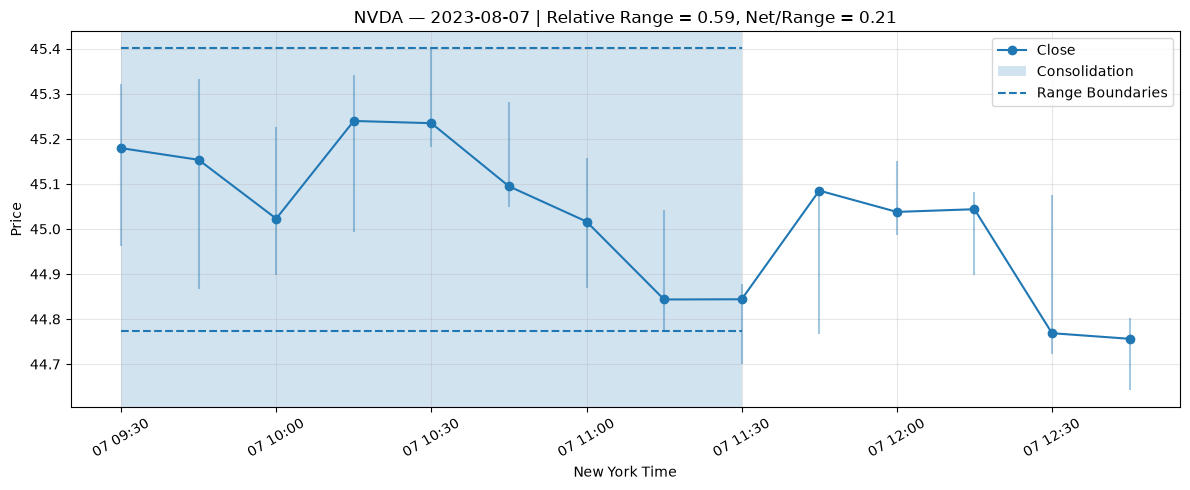

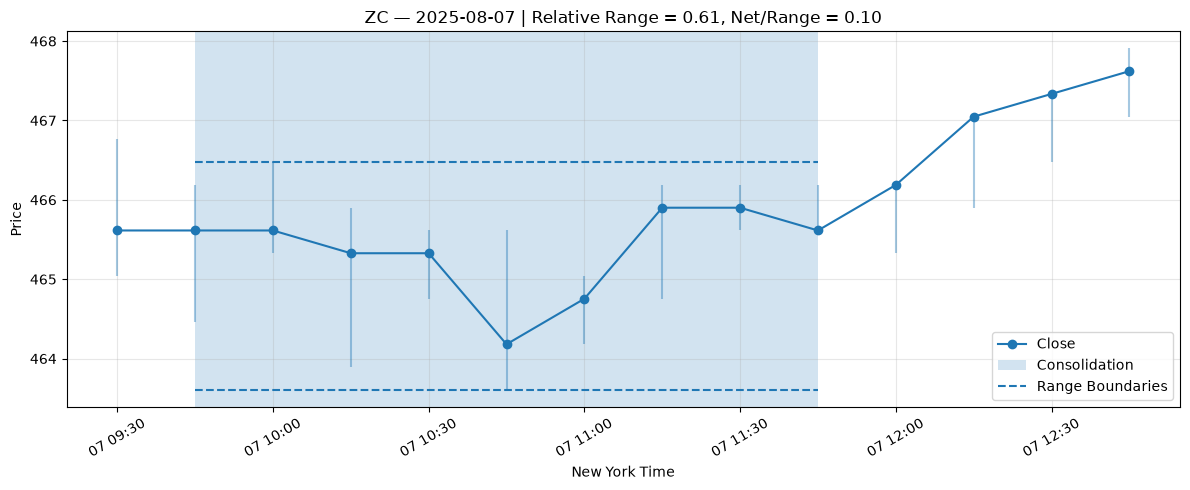

In [54]:
for ticker in ["NVDA", "ZC"]:

    # Все обнаруженные консолидации инструмента
    signals = consolidation_data[
        (consolidation_data["ticker"] == ticker)
        & consolidation_data["consolidation_signal"]
    ].sort_values("relative_range")

    if signals.empty:
        print(f"No consolidation signals for {ticker}")
        continue

    # Пример с медианным Relative Range среди сигналов
    signal = signals.iloc[len(signals) // 2]

    # Торговая сессия, в которой обнаружена консолидация
    session = consolidation_data[
        (consolidation_data["ticker"] == ticker)
        & (consolidation_data["ny_date"] == signal["ny_date"])
        & (consolidation_data["segment"] == signal["segment"])
    ].sort_values("time").reset_index(drop=True)

    # Находим свечу, на которой появился сигнал
    idx = session.index[
        session["time"] == signal["time"]
    ][0]

    # Последние 8 свечей
    window = session.iloc[
        idx - N_BARS + 1:idx + 1
    ]

    # Время Нью-Йорка
    ny_time = session["time"].dt.tz_convert(
        "America/New_York"
    )

    start = window["time"].iloc[0].tz_convert(
        "America/New_York"
    )

    # Конец последней 15-минутной свечи
    end = window["time"].iloc[-1].tz_convert(
        "America/New_York"
    ) + pd.Timedelta(minutes=15)

    # Границы ценового диапазона
    upper = window["high"].max()
    lower = window["low"].min()

    # График
    fig, ax = plt.subplots(figsize=(12, 5))

    # Диапазоны High-Low каждой свечи
    ax.vlines(
        ny_time,
        session["low"],
        session["high"],
        alpha=0.4
    )

    # Цены закрытия
    ax.plot(
        ny_time,
        session["close"],
        marker="o",
        label="Close"
    )

    # Выделяем обнаруженную консолидацию
    ax.axvspan(
        start,
        end,
        alpha=0.2,
        label="Consolidation"
    )

    # Верхняя и нижняя границы
    ax.hlines(
        [upper, lower],
        xmin=start,
        xmax=end,
        linestyles="dashed",
        label="Range Boundaries"
    )

    ax.set_title(
        f"{ticker} — {signal['ny_date']} | "
        f"Relative Range = {signal['relative_range']:.2f}, "
        f"Net/Range = {signal['net_fraction']:.2f}"
    )

    ax.set_xlabel("New York Time")
    ax.set_ylabel("Price")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

### Основные выводы по определнию консолидаций 

Для выявления консолидаций разработан алгоритм на основе исторической ширины ценового диапазона и величины направленного движения.

При базовых порогах консолидационные сигналы обнаруживаются примерно в 9-11% исследуемых окон. Частота сигналов существенно зависит от выбранных порогов, однако остаётся сопоставимой между акциями и фьючерсами.

Во время обнаруженных консолидаций наблюдается снижение относительного объёма торгов на 20-28% по сравнению с остальными периодами. Эта закономерность выявлена у всех 42 инструментов.

Значение для ML: Relative Range, Net Movement и RVOL могут использоваться как признаки для прогнозирования последующих ценовых движений

Ограничение: пороги алгоритма выбраны эвристически, а обнаруженные сигналы ещё не прошли независимую проверку качества.

# Общие выводы разведочного анализа данных 
В рамках EDA исследованы 42 финансовых инструмента: 30 акций из трёх секторов (Information Technology, Energy, Real Estate) и 12 фьючерсов (Agriculture, Currencies) за период 2021–2026 годов.

1. **Исторические данные были подтверждены качественными**: проверка исторических данных, выгруженных через Massive API, подтвердила их высокое качество и пригодность для дальнейшего анализа 

1. **Волатильность существенно различается между группами инструментов:** наиболее волатильны технологические акции, наименее - валютные фьючерсы. При этом все группы характеризуются распределениями доходностей с тяжёлыми хвостами, указывающими на повышенную частоту экстремальных движений по сравнению с нормальным распределением.

2. **Волатильность зависит от времени суток:** Для акций в первый час основной торговой сессии США она приблизительно в 2,2-2,7 раза выше, чем в период 12:00-13:00. Закономерность сохраняется в разные годы. Фьючерсы демонстрируют менее однородную внутридневную динамику.

3. **Частота сигналов консолидации существенно зависит от выбранных порогов:** при базовом определении консолидации сигналы обнаруживаются приблизительно в 9-11% подходящих восьмисвечных окон. При этом частота остаётся сопоставимой между группами инструментов после нормализации диапазона относительно исторических значений.

4. **Обнаруженные отрезки консолидации совпали со снижением медианного RVOL:** во всех 42 инструментах обнаруженные консолидации сопровождаются снижением медианного относительного объёма торгов (RVOL). Разница между периодами консолидации и остальными наблюдениями составляет приблизительно 20–28% в зависимости от группы.

5. **Классификация рыночных режимов существенно зависит от выбранных индикаторов и пороговых значений:**ADX и CHOP целесообразно рассматривать как непрерывные признаки, характеризующие силу тренда и направленность движения, а не использовать их пороговые значения как единственный способ определения рыночных режимов. Их предсказательную ценность необходимо проверить при обучении моделей

